In [5]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def sobel(img):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("No se pudo leer la imagen.")

    filas, columnas = img.shape
    salida = np.zeros_like(img, dtype=float)

    for i in range(1, filas - 1):
        for j in range(1, columnas - 1):
            C = ((img[i-1, j+1] + 2*img[i, j+1] + img[i+1, j+1]) -
                 (img[i-1, j-1] + 2*img[i, j-1] + img[i+1, j-1]))

            F = ((img[i-1, j-1] + 2*img[i-1, j] + img[i-1, j+1]) -
                 (img[i+1, j-1] + 2*img[i+1, j] + img[i+1, j+1]))

            salida[i, j] = np.sqrt(C**2 + F**2)

    salida = np.clip(salida, 0, 255).astype(np.uint8)
    return salida


In [6]:
im_test = np.array([
    [ 12,  58, 130,  90,  15],
    [200,  85,  45, 210,  60],
    [ 33, 120, 255, 100,  10],
    [ 77,  25, 180,  95, 220],
    [150,  60,  35, 140,  80]
], dtype=np.uint8)


print(sobel(im_test))


[[  0   0   0   0   0]
 [  0 255 255 255   0]
 [  0 255 181 255   0]
 [  0 255 255 138   0]
 [  0   0   0   0   0]]


In [7]:
#TAREA22

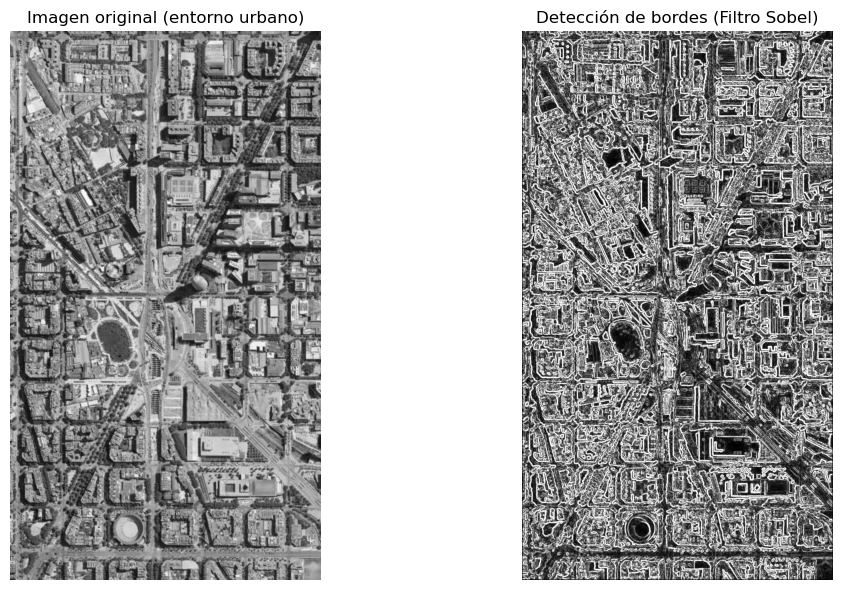

In [8]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread("Barcelona.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("No se pudo leer la imagen. Verifica el nombre o la ruta.")

img_sobel = sobel(img)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original (entorno urbano)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_sobel, cmap='gray')
plt.title("Detección de bordes (Filtro Sobel)")
plt.axis('off')

plt.tight_layout()
plt.show()
